[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/03_integrators_timestep.ipynb)

# 03 · Integrators, Timestep, and Energy Conservation

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~60 min*

How big can a time step be before a simulation becomes wrong, or explodes? We answer this twice. First we
write a complete MD code for **liquid argon** in NumPy (periodic box, Lennard-Jones forces, velocity
Verlet) and measure energy conservation. Then we run the same physics in **OpenMM** and move to a real
molecule, alanine dipeptide, to see how **constraints** and **hydrogen mass repartitioning (HMR)** let modern
simulations use 2–4 fs steps.

**Learning objectives.** By the end of this notebook you will be able to:

- write a small but complete MD engine for a Lennard-Jones liquid
- use total-energy conservation in NVE as the health check of an integrator and timestep
- run the same system in OpenMM and compare
- explain how bond constraints (SHAKE/SETTLE) and HMR allow 2 fs and 4 fs time steps

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Liquid argon in reduced units

Argon atoms interact only through Lennard-Jones: $\sigma = 0.3405$ nm and $\varepsilon = 0.996$ kJ/mol
(Rahman's classic 1964 parameters; the first MD simulation of a real liquid). We place 108 atoms on a
face-centred cubic lattice at the density of liquid argon and give them random velocities for ~120 K.
The box is **periodic** (an atom leaving one side re-enters on the other; Notebook 05) and each atom only
sees the nearest image of the others (**minimum image convention**).

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SIGMA, EPS, MASS = 0.3405, 0.996, 39.948     # nm, kJ/mol, amu
KB = 0.0083144626                             # kJ/mol/K
N_CELL = 3
N = 4 * N_CELL**3                             # 108 atoms
RHO_STAR, T = 0.8, 120.0                      # reduced density, kelvin
L = (N / RHO_STAR) ** (1 / 3) * SIGMA         # box edge (nm)
RC = 2.5 * SIGMA                              # cutoff

def fcc_lattice(n_cell, box):
    a = box / n_cell
    base = np.array([[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]])
    cells = np.array([[i, j, k] for i in range(n_cell) for j in range(n_cell) for k in range(n_cell)])
    return ((cells[:, None, :] + base[None, :, :]).reshape(-1, 3) + 0.25) * a

rng = np.random.default_rng(42)
x0 = fcc_lattice(N_CELL, L)
v0 = rng.normal(0, np.sqrt(KB * T / MASS), (N, 3))
v0 -= v0.mean(axis=0)                         # no net drift of the whole box
density = N * MASS / 6.02214076e23 / (L * 1e-7) ** 3
tau = SIGMA * np.sqrt(MASS / EPS)
print(f"{N} atoms, box {L:.3f} nm, density {density:.3f} g/cm3, LJ time unit {tau:.2f} ps")

108 atoms, box 1.747 nm, density 1.344 g/cm3, LJ time unit 2.16 ps


10 ps in 1.2 s; final T = 120.6 K


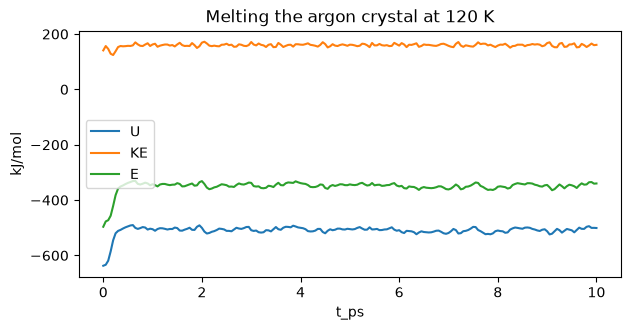

In [3]:
E_SHIFT = 4 * EPS * ((SIGMA / RC) ** 12 - (SIGMA / RC) ** 6)   # makes U(rc) = 0

def lj_forces(x, shift=True):
    d = x[:, None, :] - x[None, :, :]            # all pair vectors (N, N, 3)
    d -= L * np.round(d / L)                     # minimum image
    r2 = (d ** 2).sum(-1)
    np.fill_diagonal(r2, np.inf)
    mask = r2 < RC ** 2
    inv6 = np.where(mask, (SIGMA ** 2 / r2) ** 3, 0.0)
    u = np.where(mask, 4 * EPS * (inv6 ** 2 - inv6) - (E_SHIFT if shift else 0.0), 0.0)
    fmag = np.where(mask, 24 * EPS * (2 * inv6 ** 2 - inv6) / r2, 0.0)   # |F|/r
    f = (fmag[:, :, None] * d).sum(axis=1)
    return f, 0.5 * u.sum()

def run_nve(x, v, dt, n_steps, every=10, target_T=None):
    # Velocity Verlet. With target_T, velocities are rescaled to that temperature every 10 steps
    # (a crude thermostat we use only to equilibrate; Notebook 04 does this properly).
    x, v = x.copy(), v.copy()
    f, u = lj_forces(x)
    out = []
    for step in range(n_steps + 1):
        if step % every == 0:
            ke = 0.5 * MASS * (v ** 2).sum()
            out.append((step * dt, u, ke, u + ke, 2 * ke / (3 * N - 3) / KB))
        if step == n_steps:
            break
        v += 0.5 * dt * f / MASS
        x += dt * v
        x %= L                                   # wrap into the box
        f, u = lj_forces(x)
        v += 0.5 * dt * f / MASS
        if target_T and step % 10 == 0:
            v *= np.sqrt(target_T / (2 * 0.5 * MASS * (v ** 2).sum() / (3 * N - 3) / KB))
    return pd.DataFrame(out, columns=["t_ps", "U", "KE", "E", "T"]), x, v

t0 = time.time()
df, x_eq, v_eq = run_nve(x0, v0, 0.005, 2000, target_T=T)   # 5 fs steps, 10 ps: melt the lattice at 120 K
print(f"10 ps in {time.time() - t0:.1f} s; final T = {df['T'].iloc[-1]:.1f} K")
df.plot(x="t_ps", y=["U", "KE", "E"], figsize=(7, 3.2), title="Melting the argon crystal at 120 K", ylabel="kJ/mol");

As the lattice melts, kinetic energy flows into potential energy (U rises). Without the velocity rescaling
the liquid would cool to about half the starting temperature; with it, the temperature is held at 120 K, so
the total energy E is *not* conserved during this equilibration stage. Now the key experiment: switch the
rescaling off (pure NVE), start from the same liquid, and run 10 ps with different timesteps.

,std E (kJ/mol),drift (kJ/mol/ps),std KE (kJ/mol),mean T (K)
dt (fs),,,,
2,0.0015,-0.0003,7.5971,122.6205
5,0.0067,-0.0002,6.8494,122.6557
10,0.0280,0.0013,6.6889,122.9565
20,0.1123,-0.0007,7.7149,122.8337
40,0.6634,0.1349,7.0362,121.9439


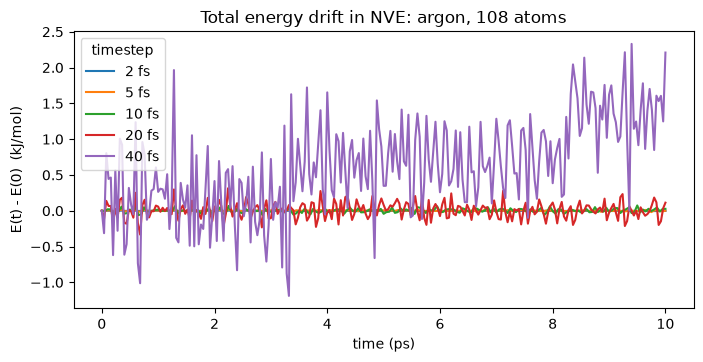

In [4]:
results, curves = [], {}
for dt_fs in [2, 5, 10, 20, 40]:
    dt = dt_fs / 1000
    d, _, _ = run_nve(x_eq, v_eq, dt, int(10 / dt), every=max(1, int(0.05 / dt)))
    drift = np.polyfit(d.t_ps, d.E, 1)[0]            # kJ/mol per ps
    results.append({"dt (fs)": dt_fs, "std E (kJ/mol)": d.E.std(), "drift (kJ/mol/ps)": drift,
                    "std KE (kJ/mol)": d.KE.std(), "mean T (K)": d["T"].mean()})
    curves[dt_fs] = d
res = pd.DataFrame(results).set_index("dt (fs)")
display(res.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
for dt_fs, d in curves.items():
    ax.plot(d.t_ps, d.E - d.E.iloc[0], label=f"{dt_fs} fs")
ax.set(xlabel="time (ps)", ylabel="E(t) - E(0)  (kJ/mol)", title="Total energy drift in NVE: argon, 108 atoms")
ax.legend(title="timestep"); plt.show()

A useful rule: the fluctuation of the total energy should be **much smaller** than the fluctuation of the
kinetic energy, and there should be no systematic drift. Small steps pass easily. As the step grows the
error grows roughly as $\Delta t^2$, and once atoms move too far in one step (they collide with the
$r^{-12}$ wall) the energy jumps and the simulation is no longer physical. For argon (no bonds, heavy atoms)
around 10 fs is fine; molecules with hydrogen need much smaller steps.

## 2. The same argon box in OpenMM

OpenMM needs a `System` (particles, masses, forces), an integrator, and a platform. We build argon by
hand with a `NonbondedForce` and check that the energy of our starting liquid matches the NumPy code
(without the energy shift, since OpenMM's plain cutoff does not shift the potential).

In [5]:
import openmm
from openmm import unit

def argon_system():
    system = openmm.System()
    system.setDefaultPeriodicBoxVectors(openmm.Vec3(L, 0, 0), openmm.Vec3(0, L, 0), openmm.Vec3(0, 0, L))
    nbf = openmm.NonbondedForce()
    nbf.setNonbondedMethod(openmm.NonbondedForce.CutoffPeriodic)
    nbf.setCutoffDistance(RC)
    nbf.setUseDispersionCorrection(False)
    for _ in range(N):
        system.addParticle(MASS)
        nbf.addParticle(0.0, SIGMA, EPS)
    system.addForce(nbf)
    return system

ctx = openmm.Context(argon_system(), openmm.VerletIntegrator(0.005), openmm.Platform.getPlatformByName("Reference"))
ctx.setPositions(x_eq)
u_openmm = ctx.getState(getEnergy=True).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
print(f"NumPy U = {lj_forces(x_eq, shift=False)[1]:.4f} kJ/mol | OpenMM U = {u_openmm:.4f} kJ/mol")

NumPy U = -546.6699 kJ/mol | OpenMM U = -546.6699 kJ/mol


In [6]:
def openmm_nve(system, positions, velocities, dt_ps, total_ps, every_ps=0.05, platform="CPU"):
    integ = openmm.VerletIntegrator(dt_ps)
    c = openmm.Context(system, integ, openmm.Platform.getPlatformByName(platform))
    c.setPositions(positions); c.setVelocities(velocities)
    rows, nper = [], max(1, round(every_ps / dt_ps))
    for k in range(round(total_ps / (nper * dt_ps)) + 1):
        if k:
            integ.step(nper)
        s = c.getState(getEnergy=True)
        ke = s.getKineticEnergy().value_in_unit(unit.kilojoule_per_mole)
        pe = s.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
        rows.append((k * nper * dt_ps, pe, ke, pe + ke))
    return pd.DataFrame(rows, columns=["t_ps", "U", "KE", "E"])

t0 = time.time()
d_omm = openmm_nve(argon_system(), x_eq, v_eq, 0.005, 10)
print(f"OpenMM, 10 ps at 5 fs in {time.time() - t0:.2f} s | std E = {d_omm.E.std():.4f}, std KE = {d_omm.KE.std():.3f} kJ/mol")

OpenMM, 10 ps at 5 fs in 0.92 s | std E = 0.2346, std KE = 7.560 kJ/mol


The plain cutoff makes the energy jump slightly every time a pair crosses $r_c$, so OpenMM's total energy
fluctuates a bit more than our shifted version. That is why real force fields use a **switching function**
or long-range methods (Notebook 05). Same physics, but OpenMM is compiled and parallel: it scales to proteins
in water, which we cannot do in NumPy.

## 3. A real molecule: constraints and hydrogen mass repartitioning

Now alanine dipeptide in vacuum (22 atoms, AMBER ff14SB). We run NVE with:

- **no constraints**: hydrogen atoms vibrate freely (the ~11 fs C–H period of Notebook 01);
- **`HBonds` constraints**: every bond to hydrogen is held at fixed length (SHAKE/CCMA in OpenMM);
- **HBonds + HMR**: also move 0.5 amu of mass from each heavy atom onto its hydrogens (H mass 1.5 amu),
  which slows the remaining fast motions so a **4 fs** step is stable. Total mass is unchanged, so
  equilibrium (thermodynamic) properties are unchanged; only fast dynamics are slightly modified.

In [7]:
from openmm import app

pdb = app.PDBFile(f"{DATA_DIR}/structures/alanine_dipeptide.pdb")
ff = app.ForceField("amber14-all.xml")

# start from a minimized, 300 K structure (velocities from a short equilibration)
base = ff.createSystem(pdb.topology, nonbondedMethod=app.NoCutoff, constraints=app.HBonds)
eq = openmm.LangevinMiddleIntegrator(300, 1.0, 0.002); eq.setRandomNumberSeed(1)
c = openmm.Context(base, eq, openmm.Platform.getPlatformByName("CPU"))
c.setPositions(pdb.positions); openmm.LocalEnergyMinimizer.minimize(c)
c.setVelocitiesToTemperature(300, 7); eq.step(5000)
st = c.getState(getPositions=True, getVelocities=True)
x_ala, v_ala = st.getPositions(), st.getVelocities()

settings = [("no constraints", None, 1.0, 0.5), ("no constraints", None, 1.0, 1.0),
            ("no constraints", None, 1.0, 2.0), ("HBonds", app.HBonds, 1.0, 2.0),
            ("HBonds", app.HBonds, 1.0, 4.0), ("HBonds + HMR", app.HBonds, 1.5, 4.0)]
rows = []
for label, cons, hmass, dt_fs in settings:
    system = ff.createSystem(pdb.topology, nonbondedMethod=app.NoCutoff, constraints=cons,
                             hydrogenMass=hmass * unit.amu if hmass > 1.0 else None)
    try:
        d = openmm_nve(system, x_ala, v_ala, dt_fs / 1000, 20.0, every_ps=0.02)
        ok = np.isfinite(d.E).all() and d.E.abs().max() < 1e5
        rows.append({"setup": label, "dt (fs)": dt_fs, "std E": d.E.std() if ok else np.nan,
                     "drift (kJ/mol/ns)": np.polyfit(d.t_ps, d.E, 1)[0] * 1000 if ok else np.nan,
                     "std KE": d.KE.std(), "stable": bool(ok)})
    except openmm.OpenMMException as err:
        rows.append({"setup": label, "dt (fs)": dt_fs, "stable": False, "error": str(err)[:60]})
table = pd.DataFrame(rows)
table["std E / std KE"] = table["std E"] / table["std KE"]
table.round(3)

,setup,dt (fs),std E,drift (kJ/mol/ns),std KE,stable,std E / std KE
0,no constraints,0.5,0.039,0.326,6.714,True,0.006
1,no constraints,1.0,0.207,-5.286,6.819,True,0.030
2,no constraints,2.0,0.884,-17.543,6.985,True,0.127
3,HBonds,2.0,0.397,-0.392,7.227,True,0.055
4,HBonds,4.0,2.206,44.628,7.319,True,0.301
5,HBonds + HMR,4.0,2.148,-15.116,8.507,True,0.252


Read the table row by row. Without constraints the energy error grows quickly with the step, because the
fast hydrogen vibrations are poorly integrated. Constraining bonds to H roughly halves the error at
2 fs. At 4 fs the energy error is clearly larger again, with or without HMR, so in strict NVE
terms 4 fs is a compromise. HMR's real job is **stability**: in solvated proteins, 4 fs without HMR can
fail (fast H-containing angle motions get resonantly excited), while 4 fs with HMR runs robustly when a
thermostat absorbs the small integration error (Hopkins *et al.*, *J. Chem. Theory Comput.* 2015,
doi:10.1021/ct5010406). Equilibrium properties are unchanged because total masses are unchanged; only
sampling per nanosecond doubles. This is the setting (HBonds + HMR + 4 fs + Langevin) used for the
precomputed trajectories in this course; for strict NVE work, 2 fs with HBonds is the safer choice.

**What about thermostats?** In practice we rarely run pure NVE. OpenMM's recommended integrator is
`LangevinMiddleIntegrator`, a velocity-Verlet-like scheme that adds friction and random kicks to hold the
temperature (Notebook 04). The timestep rules you learned here still apply to it.

### ✏️ Exercise 1

For the argon NumPy code, compute the **ratio** `std(E) / std(KE)` for each timestep in `res` and find the
largest timestep for which it stays below 0.05 (a common acceptance criterion).

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
res["ratio"] = res["std E (kJ/mol)"] / res["std KE (kJ/mol)"]
print(res["ratio"].round(4))
print("largest acceptable dt:", res.index[res["ratio"] < 0.05].max(), "fs")
```

</details>

### ✏️ Exercise 2

The OpenMM argon energy fluctuates partly because of the abrupt cutoff. Turn on a switching function
(`nbf.setUseSwitchingFunction(True)` and `nbf.setSwitchingDistance(0.9 * RC)`) inside a copy of `argon_system()`
and compare `std E` for a 10 ps NVE run at 5 fs.

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
s = argon_system()
nbf = s.getForce(0)
nbf.setUseSwitchingFunction(True); nbf.setSwitchingDistance(0.9 * RC)
d_sw = openmm_nve(s, x_eq, v_eq, 0.005, 10)
print(f"plain cutoff std E = {d_omm.E.std():.4f} | switched std E = {d_sw.E.std():.4f} kJ/mol")
```

</details>

### ✏️ Exercise 3

Count the **degrees of freedom** removed by constraints: build the alanine dipeptide system with
`constraints=app.HBonds` and print `system.getNumConstraints()`. How many hydrogen atoms does the molecule
have? Why are the two numbers equal?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
s = ff.createSystem(pdb.topology, nonbondedMethod=app.NoCutoff, constraints=app.HBonds)
n_h = sum(a.element.symbol == "H" for a in pdb.topology.atoms())
print("constraints:", s.getNumConstraints(), "| hydrogens:", n_h)
# Every hydrogen has exactly one bond, and HBonds constrains each of those bonds.
```

</details>

## Key takeaways

- Total-energy conservation in NVE is the basic test of an integrator and timestep.
- Error grows roughly as Δt²; too large a step makes atoms collide and the simulation blows up.
- Heavy atoms only (argon): ~10 fs. Molecules with H: 1 fs free, 2 fs with HBonds constraints, 4 fs with HBonds + HMR.
- OpenMM gives the same physics as hand-written code, but fast and scalable.

**Next:** [04 · Thermostats, barostats, and ensembles](04_thermostats_barostats_ensembles.ipynb).